# Módulo 7 — Cointegração
## Seção 7.6 — Modelos vetoriais de correção de erros (VECM)

**Estado editorial:** capítulo de estudo para revisão matemática e bibliográfica. **Pré-requisitos:** §§7.1–7.5, especialmente regressão espúria, processos $I(1)$, cointegração, ECM, VAR e teste de Johansen; vetores, multiplicação de matrizes e posto. **Ambiente:** Python 3, NumPy, Matplotlib e Statsmodels. **Natureza dos dados:** exclusivamente sintéticos.

**Rastreabilidade bibliográfica.** Morettin e Toloi, *Análise de séries temporais: modelos lineares univariados*, v. 1, 3. ed. (2018), cap. 5 e Apêndice B, fundamentam **apenas os pré-requisitos univariados** de integração, diferenças e raízes unitárias. A formulação VECM e a interpretação multivariada são **complementação teórica externa** baseada em Engle e Granger (1987), Johansen (1988, 1991) e na implementação `statsmodels.tsa.vector_ar.vecm`. As demonstrações algébricas e os dados deste texto são desenvolvimentos didáticos originais. Não atribuímos VECM a páginas do volume univariado.

### Objetivos de aprendizagem

Ao terminar esta seção, você deverá conseguir (1) reescrever um VAR em forma VECM; (2) distinguir relações de longo prazo de coeficientes de ajuste; (3) explicar o posto de cointegração e a normalização; (4) resolver manualmente uma atualização com duas séries; (5) simular e ajustar um VECM; (6) interpretar corretamente saídas do Statsmodels; (7) reconhecer limites de identificação, inferência, diagnóstico e previsão.

### 1. O problema que o VECM resolve

Quando duas ou mais séries compartilham tendências estocásticas, modelá-las **somente em níveis** pode levar a interpretações equivocadas se tratarmos o VAR como estacionário; modelá-las **somente em primeiras diferenças** pode descartar a relação de equilíbrio que mantém suas trajetórias conectadas. O VECM combina essas duas escalas de variação.

Imagine duas medidas econômicas, $y_{1t}$ e $y_{2t}$, com uma relação estável $y_{1t}\approx 2y_{2t}$. Cada série pode ser $I(1)$, enquanto o desvio

$$
u_t=y_{1t}-2y_{2t}$$

pode ser $I(0)$. O VECM utiliza $\nu_{t-1}$ para explicar parte das mudanças de $\mathbf y_t=(y_{1t},y_{2t})^\top$, sem confundir essa relação estatística com causalidade.

### 2. Revisão e dedução: de VAR(2) a VECM

Suponha um VAR(2) de $p$ variáveis, inicialmente sem termos determinísticos:

$$\mathbf y_t=A_1\mathbf y_{t-1}+A_2\mathbf y_{t-2}+\boldsymbol\varepsilon_t,$$

com $A_1,A_2\in\mathbb R^{p\times p}$. Subtraímos $\mathbf y_{t-1}$:

$$\Delta\mathbf y_t=(A_1-I_p)\mathbf y_{t-1}+A_2\mathbf y_{t-2}+\boldsymbol\varepsilon_t.$$

Usando $\mathbf y_{t-2}=\mathbf y_{t-1}-\Delta\mathbf y_{t-1}$:

$$\begin{aligned}
\Delta\mathbf y_t
&=(A_1-I_p)\mathbf y_{t-1}+A_2(\mathbf y_{t-1}-\Delta\mathbf y_{t-1})+\boldsymbol\varepsilon_t\\
&=(A_1+A_2-I_p)\mathbf y_{t-1}-A_2\Delta\mathbf y_{t-1}+\boldsymbol\varepsilon_t.
\end{aligned}$$

Defina $\Pi=A_1+A_2-I_p$ e $\Gamma_1=-A_2$. Portanto,

$$\boxed{\Delta\mathbf y_t=\Pi\mathbf y_{t-1}+\Gamma_1\Delta\mathbf y_{t-1}+\boldsymbol\varepsilon_t.}$$

Para VAR($k$), a identidade geral é

$$\boxed{\Delta\mathbf y_t=\Pi\mathbf y_{t-1}+\sum_{j=1}^{k-1}\Gamma_j\Delta\mathbf y_{t-j}+\mathbf d_t+\boldsymbol\varepsilon_t,}$$

com $\Pi=\sum_{i=1}^{k}A_i-I_p$ e $\Gamma_j=-\sum_{i=j+1}^{k}A_i$. A sequência $\mathbf d_t$ contempla os termos determinísticos especificados. **Importante:** toda a reescrita é algébrica; ela **não prova** que existe cointegração.

### 3. A restrição de posto e a fatoração $\Pi=\alpha\beta^\top$

Para um sistema $I(1)$ regular de dimensão $p$, se $0<r=\operatorname{rank}(\Pi)<p$, podemos fatorar

$$\boxed{\Pi=\alpha\beta^\top,\qquad\alpha,\beta\in\mathbb R^{p\times r}.}$$

As duas matrizes têm posto coluna $r$, e a representação torna-se

$$\boxed{\Delta\mathbf y_t=\underbrace{\alpha\beta^\top\mathbf y_{t-1}}_{\text{correção do equilíbrio}}+\underbrace{\sum_{j=1}^{k-1}\Gamma_j\Delta\mathbf y_{t-j}}_{\text{dinâmica de curto prazo}}+\mathbf d_t+\boldsymbol\varepsilon_t.}$$

A matriz **$\beta$** contém nas colunas os **vetores cointegrantes**; $\beta^\top\mathbf y_{t-1}\in\mathbb R^r$ contém os desvios das $r$ relações estacionárias. A matriz **$\alpha$** traduz cada desvio em mudanças das $p$ variáveis; suas linhas dizem como cada equação reage. $\Gamma_j$ descrevem a resposta às mudanças defasadas. A matriz de covariância de $\boldsymbol\varepsilon_t$ descreve a dispersão conjunta das inovações, e não deve ser confundida com $\Pi$.

O número $p-r$ corresponde, sob as hipóteses usuais do sistema $I(1)$, ao número de tendências estocásticas comuns. Os casos limites são $r=0$ (sem termo de correção, $\Pi=0$) e $r=p$ (posto completo; não estamos no caso usual de níveis $I(1)$ com $p-r$ tendências comuns). A interpretação do posto depende de condições adicionais de regularidade e da ausência de raízes unitárias de ordem maior.

**Por que a fatoração não é única?** Para uma matriz invertível $H\in\mathbb R^{r\times r}$,

$$\widetilde\alpha=\alpha H,\qquad\widetilde\beta=\beta H^{-\top}$$

satisfazem $\widetilde\alpha\widetilde\beta^\top=\alpha\beta^\top$. Logo, os vetores precisam de uma **normalização** para permitir comparação, sem alterar o espaço cointegrante ou as previsões do mesmo modelo. No caso $r=1$, multiplicar $\beta$ por $c\ne0$ exige dividir $\alpha$ por $c$.

### 4. Exemplo numérico resolvido: duas equações ajustam-se ao mesmo desvio

Considere $p=2$, $r=1$, sem intercepto e sem defasagens das diferenças:

$$\beta=\begin{pmatrix}1\\-2\end{pmatrix},\qquad
\alpha=\begin{pmatrix}-0{,}3\\0{,}1\end{pmatrix}.$$

Assim,

$$\Pi=\alpha\beta^\top=\begin{pmatrix}-0{,}3&0{,}6\\0{,}1&-0{,}2\end{pmatrix}.$$

A segunda linha de $\Pi$ é $-1/3$ da primeira; seu determinante é zero e $\Pi\ne0$. Portanto $\operatorname{rank}(\Pi)=1$. As duas equações do VECM são

$$\begin{aligned}
\Delta y_{1t}&=-0{,}3(y_{1,t-1}-2y_{2,t-1})+\varepsilon_{1t},\\
\Delta y_{2t}&=\phantom{-}0{,}1(y_{1,t-1}-2y_{2,t-1})+\varepsilon_{2t}.
\end{aligned}$$

Se o desvio anterior vale $\nu_{t-1}=2$ e, **somente para a conta manual**, as inovações atuais são zero, então $\Delta y_{1t}=-0{,}6$ e $\Delta y_{2t}=0{,}2$. O novo desvio é

$$\begin{aligned}\nu_t&=\nu_{t-1}+\Delta y_{1t}-2\Delta y_{2t}\\&=2-0{,}6-2(0{,}2)=1.\end{aligned}$$

O sistema reduziu o afastamento de 2 para 1 neste passo. Não se trata de “30% do equilíbrio corrigido”: o desvio resulta do **ajuste conjunto** das duas equações. Formalmente, multiplicando o VECM por $\beta^\top$:

$$\nu_t=\underbrace{(1+\beta^\top\alpha)}_{\phi}\nu_{t-1}+\beta^\top\boldsymbol\varepsilon_t.$$

Como $\beta^\top\alpha=-0{,}3-2(0{,}1)=-0{,}5$, então $\phi=0{,}5$. Com inovações de segunda ordem estacionárias e condições apropriadas, $\nu_t$ é um AR(1) estacionário porque $|\phi|<1$. Observe que o sinal negativo de um elemento isolado de $\alpha$ **não garante** a estabilidade do sistema; é preciso examinar a dinâmica relevante.

### 5. Construção e implementação progressiva em Python

Primeiro escrevemos a regra de evolução manualmente. Para esta simulação, usamos as mesmas matrizes do exemplo e ruídos gaussianos independentes em cada período. Os níveis compartilham uma tendência estocástica, enquanto a combinação $y_{1t}-2y_{2t}$ é estacionária na solução adequada. A inicialização em zero é uma condição transiente, não uma amostra exatamente estacionária de $\nu_t$ desde $t=0$.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(20261122)
n, descarte = 900, 150
alpha_verd = np.array([[-0.3], [0.1]])  # (2, 1)
beta_verd = np.array([[1.0], [-2.0]])  # (2, 1)
Pi = alpha_verd @ beta_verd.T

# A observação em t usa os níveis no instante t-1.
y = np.zeros((n + descarte, 2))
eps = rng.normal(scale=[0.6, 0.5], size=y.shape)
for t in range(1, len(y)):
    dy = Pi @ y[t-1] + eps[t]
    y[t] = y[t-1] + dy

Y = y[descarte:]
spread = Y @ beta_verd[:, 0]
print('Posto de Pi:', np.linalg.matrix_rank(Pi))
print('Média e DP amostral do desvio:', round(spread.mean(),3), round(spread.std(),3))
assert np.linalg.matrix_rank(Pi) == 1

**Entendendo o código.** `@` calcula o produto matricial; `Pi @ y[t-1]` é o vetor de duas correções; `eps[t]` contém as duas inovações; `np.linalg.matrix_rank` verifica o posto numérico. `Y @ beta_verd[:,0]` implementa $\beta^\top\mathbf y_t$ para cada instante. O descarte dos primeiros valores reduz a influência da inicialização; não constitui teste de cointegração.

#### 5.1 Ajustando o VECM com Statsmodels

É necessário **fixar ou selecionar justificadamente** o posto de cointegração, a ordem de defasagens e os determinísticos. Para tornar a comparação pedagógica limpa, ajustaremos exatamente a classe geradora: posto 1, nenhum determinístico e nenhuma diferença defasada. Em dados reais essas escolhas precisariam ser investigadas, por exemplo com testes e critérios de informação no período de treinamento.

In [ ]:
from statsmodels.tsa.vector_ar.vecm import VECM

modelo = VECM(Y, k_ar_diff=0, coint_rank=1, deterministic='n')
resultado = modelo.fit()

# Com r=1, normalizamos a primeira coordenada de beta para 1,
# compensando a escala em alpha para preservar alpha @ beta.T.
beta_estim = resultado.beta[:, 0]
fator = beta_estim[0]
beta_normalizado = beta_estim / fator
alpha_normalizado = resultado.alpha[:, 0] * fator

print('beta teórico:', beta_verd[:,0])
print('beta estimado (normalizado):', np.round(beta_normalizado, 3))
print('alpha teórico:', alpha_verd[:,0])
print('alpha estimado (normalizado):', np.round(alpha_normalizado, 3))
print('Erro na matriz Pi:', round(np.linalg.norm(resultado.alpha @ resultado.beta.T - Pi),4))

`VECM` estima conjuntamente os parâmetros sob a restrição de posto especificada. `k_ar_diff=0` corresponde a um VAR(1) em níveis na representação mais simples, sem termos $\Gamma_j$. `coint_rank=1` não solicita um teste automático: impõe um posto definido para o modelo. `deterministic='n'` significa que não incluímos termos determinísticos. O vetor $\beta$ pode aparecer em escala diferente, por isso normalizamos **ambas** as matrizes de maneira coerente. A estimativa variará entre simulações, mesmo quando o mecanismo gerador é conhecido.

#### 5.2 Visualização e diagnóstico introdutório

In [ ]:
residuos = np.asarray(resultado.resid)
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=False)
axes[0].plot(Y[:, 0], label='y1'); axes[0].plot(Y[:, 1], label='y2')
axes[0].set(title='Níveis de duas séries cointegradas', ylabel='Nível')
axes[0].legend()
axes[1].plot(spread, label='Desvio verdadeiro y1 − 2 y2')
axes[1].plot(Y @ beta_normalizado, '--', alpha=0.7, label='Desvio estimado')
axes[1].axhline(0, color='gray', lw=0.8)
axes[1].set(title='Combinação de longo prazo', ylabel='Desvio')
axes[1].legend()
axes[2].plot(residuos[:, 0], label='Resíduo da 1ª equação', alpha=0.8)
axes[2].plot(residuos[:, 1], label='Resíduo da 2ª equação', alpha=0.7)
axes[2].set(title='Resíduos do VECM ajustado', xlabel='Índice temporal', ylabel='Inovação estimada')
axes[2].legend()
for ax in axes:
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.savefig("figuras/07_06_vecm_simulacao.png", dpi=150, bbox_inches="tight")
plt.show()

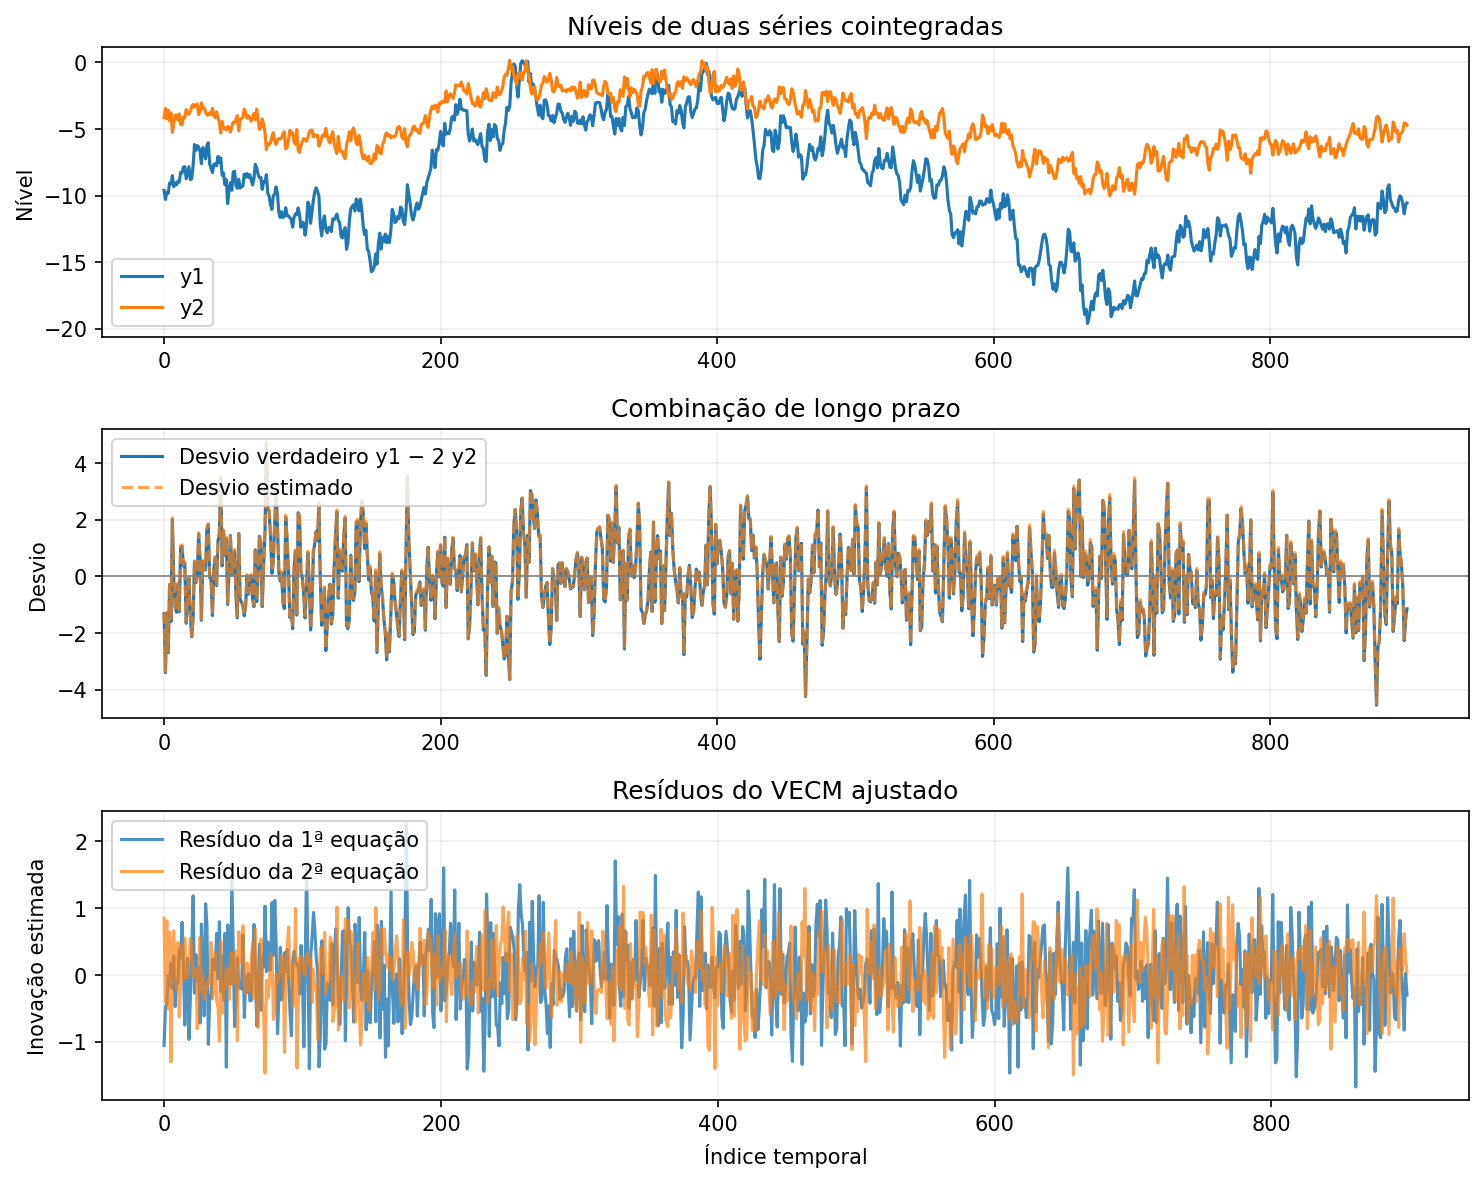

*Figura 7.6.1 — Simulação de um VECM com uma relação cointegrante, comparação do desvio verdadeiro e estimado e resíduos das duas equações. A proximidade empírica entre vetores não demonstra, isoladamente, consistência ou validade geral do estimador.*

**Diagnóstico preliminar.** Para uma aplicação científica, avaliar autocorrelação residual multivariada, estabilidade das relações de longo prazo, heterocedasticidade, normalidade quando usada para inferência, quebras estruturais e alterações nos determinísticos. Verificar só a aparência do gráfico não é diagnóstico suficiente. Cuidado: a variância do desvio pode ser estacionária sem que cada nível seja estacionário.

### 6. Previsão: por que corrigir o erro de equilíbrio importa?

A previsão condicional de um passo para o VECM simples, sob inovações de média condicional zero, é

$$E[\mathbf y_{t+1}\mid\mathcal F_t]=\mathbf y_t+\alpha\beta^\top\mathbf y_t.$$

Se a relação de equilíbrio estiver acima do nível compatível com os parâmetros, o termo de correção altera as previsões de **ambas** as variáveis. Para um VECM com $\Gamma_j$ e determinísticos, devem-se incluir esses termos conhecidos na origem da previsão. Previsões com múltiplos passos iteram a dinâmica; a incerteza aumenta com o horizonte e exige modelagem da covariância dos choques.

**Validação temporal.** Ajuste o posto, os determinísticos, $\alpha$, $\beta$ e os demais coeficientes **exclusivamente com dados de treinamento**. Uma análise retrospectiva com toda a série, seguida de avaliação no próprio conjunto, gera vazamento temporal. Comparar previsões com modelos alternativos (VAR em diferenças, modelos univariados e baselines) depende da métrica e do problema de pesquisa.

### 7. Limitações e cautelas matemáticas

1. **Posto e integração:** a interpretação padrão pressupõe sistema adequadamente descrito por componentes $I(1)$ e condições de regularidade; séries $I(2)$ requerem outro tratamento.
2. **Identificação:** $\alpha$ e $\beta$ não são únicos sem normalização. Uma relação cointegrante não demonstra causalidade econômica ou física.
3. **Determinísticos:** interceptos dentro ou fora da relação cointegrante, tendências restritas e não restritas alteram a especificação e a inferência.
4. **Dinâmica de curto prazo:** omitir $\Gamma_j$ relevantes pode causar autocorrelação residual e enviesar conclusões.
5. **Amostra finita:** o posto selecionado e os coeficientes estimados podem variar; testes têm erros de tipo I/II.
6. **Estabilidade:** a estabilidade do desvio cointegrante não é garantida pelo sinal de um coeficiente individual de $\alpha$.
7. **Fonte principal:** Morettin e Toloi (volume univariado) não substitui literatura específica de VECM.

### 8. Exercícios graduais — resolver antes de consultar o código

**1 — Conceitual.** Explique por que diferenciar todas as séries sem considerar $\beta^\top\mathbf y_{t-1}$ pode perder informação importante para previsão e interpretação de longo prazo.

**2 — Matricial.** Repita a multiplicação $\alpha\beta^\top$ para $\alpha=(-0{,}2,0{,}05)^\top$ e $\beta=(1,-3)^\top$. Qual o posto da matriz? Interprete o desvio.

**3 — Dedução.** Demonstre a identidade VAR(3) → VECM e obtenha $\Pi$, $\Gamma_1$, $\Gamma_2$. Escreva primeiro os termos de $\mathbf y_{t-1}$, $\Delta\mathbf y_{t-1}$ e $\Delta\mathbf y_{t-2}$.

**4 — Interpretação da estabilidade.** No exemplo da Seção 4, calcule $1+\beta^\top\alpha$. Qual seria o resultado se $\beta^\top\alpha=-2{,}2$? A variância do desvio permaneceria constante na construção AR(1)?

**5 — Programação orientada.** Escreva pseudocódigo para gerar $\mathbf y_t$ e calcular $\nu_t$. Depois, modifique **apenas** um parâmetro de $\alpha$, verifique a nova estabilidade teórica e execute uma simulação. Compare resultados antes de interpretar.

**6 — Pesquisa aplicada.** Desenhe um protocolo para verificar se duas séries econômicas são compatíveis com um VECM: frequência regular, valores ausentes, ordem de integração, termos determinísticos, seleção de defasagens, posto, diagnóstico dos resíduos, quebras e validação cronológica.

**Conferência selecionada:** no exercício 4, com $\beta^\top\alpha=-2{,}2$, a dinâmica escalar do desvio tem coeficiente $\phi=-1{,}2$, fora do intervalo estacionário $|\phi|<1$; um ruído com variância positiva não gera solução causal estacionária estável desse AR(1).

### 9. Síntese e bibliografia

O VECM mantém simultaneamente **as variações de curto prazo** e **as relações de longo prazo**. A fatoração $\Pi=\alpha\beta^\top$ explicita esse papel: $\beta$ forma combinações de equilíbrio, $\alpha$ descreve o mecanismo de ajuste e $\Gamma_j$ modelam as diferenças defasadas. A reescrita de um VAR é algébrica; a interpretação cointegrante exige hipóteses de integração e posto, e a adequação empírica exige diagnóstico e validação temporal.

**Referência principal para pré-requisitos univariados:** MORETTIN, P. A.; TOLOI, C. M. C. *Análise de Séries Temporais: Modelos Lineares Univariados*. 3. ed. São Paulo: Blucher, 2018. v. 1, cap. 5 e Apêndice B. **Referências complementares especializadas:** ENGLE, R. F.; GRANGER, C. W. J. (1987). *Co-integration and error correction: representation, estimation, and testing*. *Econometrica*, 55(2), 251–276. JOHANSEN, S. (1988). *Statistical analysis of cointegration vectors*. *Journal of Economic Dynamics and Control*, 12(2–3), 231–254. JOHANSEN, S. (1991). *Estimation and hypothesis testing of cointegration vectors in Gaussian vector autoregressive models*. *Econometrica*, 59(6), 1551–1580. **Implementação:** Statsmodels `VECM`, versão utilizada no ambiente 0.14.6. **Exemplos, demonstrações algébricas e interpretação:** complementações didáticas originais.